**Importante:**
1. não altere o código base e as células de texto.
2. Toda e qualquer adição de código e texto explicativo deve ser feita após a última célula de texto (em novas células)
3. Sugestão: leia tudo antes de sair rodando/alterando

# Checkpoint 2 — Laboratório de Redes Neurais no MNIST

Neste checkpoint, você vai partir da rede neural implementada em aula para investigar como algumas escolhas de arquitetura e treinamento afetam o aprendizado da rede.

A base utilizada será o **MNIST**, formada por imagens de dígitos escritos à mão, de 0 a 9.

O objetivo não é apenas obter uma boa acurácia, mas registrar evidências dos testes realizados e comparar os resultados obtidos.

## Experimentos obrigatórios

Você deverá realizar dois experimentos principais:

### Experimento 1 — ReLU x Sigmoide

Neste experimento, mantenha a rede com **2 camadas ocultas** e compare o desempenho da rede usando:

- ReLU nas camadas ocultas
- Sigmoide nas camadas ocultas

Você poderá escolher livremente:

- quantidade de neurônios em cada camada oculta
- learning rate
- batch size
- número máximo de épocas

### Experimento 2 — Número de camadas ocultas

Neste experimento, use **ReLU** como ativação das camadas ocultas e compare redes com:

- 1 camada oculta
- 2 camadas ocultas
- 3 camadas ocultas

Você poderá escolher livremente:

- quantidade de neurônios em cada camada oculta
- learning rate
- batch size
- número máximo de épocas

## Base reduzida e base completa

Para os experimentos obrigatórios, utilize a base reduzida definida neste notebook.

Para a tentativa final de melhor acurácia, utilize a base completa do MNIST:

- 60.000 imagens de treino
- 10.000 imagens de teste

## Entrega

Você deverá entregar:

1. O notebook `.ipynb` com as execuções realizadas.
2. Um relatório em PDF com no máximo 2 páginas:
   - Página 1: Experimento 1 — ReLU x Sigmoide
   - Página 2: Experimento 2 — 1, 2 e 3 camadas ocultas

O relatório deve conter poucos textos, apenas:
- configurações testadas
- gráficos ou evidências dos resultados
- conclusão breve de cada experimento
- melhor acurácia obtida na base de teste

A entega deve ser feita no Forms: https://forms.gle/NGg6eZmSaNCL6WqB7

# Base de Dados: MNIST

Vamos começar trabalhando com uma das bases de dados mais clássicas de Deep Learning: o **MNIST**.

## O que é o MNIST?

O MNIST é um conjunto de imagens de dígitos escritos à mão (de 0 a 9).

Cada imagem:
- Possui tamanho **28 x 28 pixels**
- É em **escala de cinza** (valores de 0 a 255)
- Representa um único número

## O que temos na base?

- **60.000 imagens para treino**
- **10.000 imagens para teste**

Nosso objetivo será:

Dada uma imagem, prever qual número ela representa.

---

Neste checkpoint, usaremos o MNIST de duas formas:

1. Uma **base reduzida**, para permitir testes rápidos.
2. A **base completa**, para a tentativa final de melhor desempenho.

In [ ]:
#Importando as bibliotecas
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Carregando a base de dados
from tensorflow.keras.datasets import mnist

# Carregar dados
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Verificar dimensões
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


## Entendendo os dados

Os formatos retornados são:

- `X_train`: (60000, 28, 28)
- `y_train`: (60000,)

Isso significa:

- Temos **60.000 imagens**
- Cada imagem tem dimensão **28 x 28**
- Cada imagem possui um rótulo (0 a 9)

Ou seja:

Cada elemento de `X_train` é uma matriz 28x28  
Cada elemento de `y_train` é um número inteiro (classe)

---

Pense assim:

- `X_train[i]` → a imagem
- `y_train[i]` → o número que aquela imagem representa

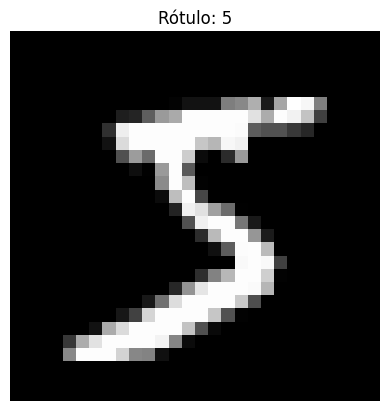

In [ ]:
#Visualizando as imagens

# Escolher um exemplo
index = 0

plt.imshow(X_train[index], cmap='gray')
plt.title(f"Rótulo: {y_train[index]}")
plt.axis('off')
plt.show()

## O que a rede realmente vê?

Embora nós vejamos um número, a rede neural recebe algo assim:

- Uma matriz 28x28 de valores entre 0 e 255

Cada valor representa a intensidade do pixel:

- 0 → preto
- 255 → branco

Para a rede, isso é apenas um conjunto de números.

---

Pergunta importante:

Se a rede recebe números, como ela consegue aprender a reconhecer padrões visuais?

(Essa pergunta vai nos acompanhar ao longo da disciplina.)

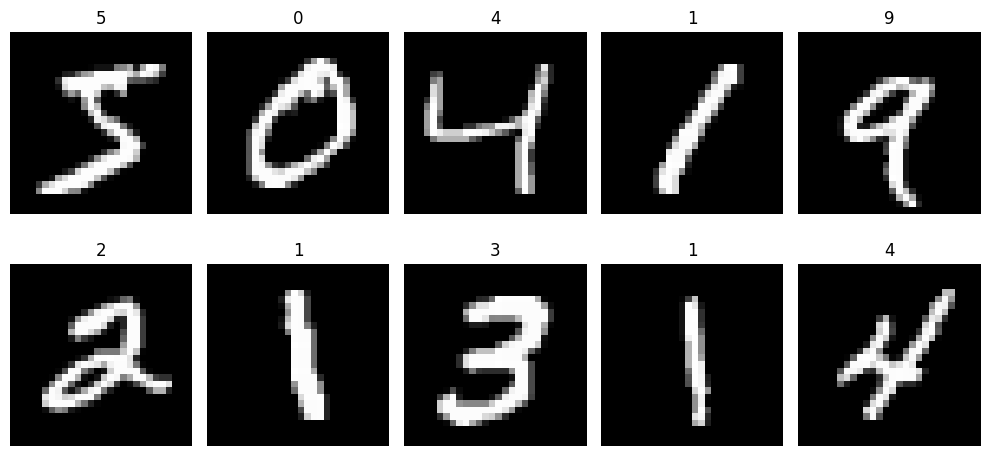

In [ ]:
#Loop para visualizar várias imagens.

plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#Agora vamos ver como a imagem está codificada na matriz numérica

index = 0

np.set_printoptions(threshold=1000)
np.set_printoptions(linewidth=200)

print(X_train[index])



[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   

## Transformando a imagem em entrada para a rede

Até agora, cada imagem está no formato: 28 x 28 (uma matriz)

Mas a nossa rede neural **não foi construída para trabalhar com matrizes**.  
Ela espera um **vetor de entrada**.

---

## O que vamos fazer?

Vamos transformar cada imagem de: 28 x 28 → 784

Ou seja, vamos **“achatar” (flatten)** a imagem.

---

Intuição:

Imagine pegar a imagem e "desenrolar" linha por linha até formar uma única sequência de números.

---

Consequência importante:

Ao fazer isso, **perdemos a estrutura espacial da imagem**.

- Pixels vizinhos deixam de ser vizinhos
- A rede não sabe mais o que está “perto” ou “longe”

Isso vai ser importante mais pra frente...

In [ ]:
# Achatar as imagens

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Neste notebook, vamos usar o padrão visto em aula:
# cada exemplo ficará em uma coluna.
#
# Assim:
# X_train_flat terá formato (784, número de exemplos)

X_train_flat = X_train_flat.T
X_test_flat = X_test_flat.T

print("Antes:", X_train.shape)
print("Depois:", X_train_flat.shape)



Antes: (60000, 28, 28)
Depois: (784, 60000)


## O que aconteceu aqui?

Antes:
- (60000, 28, 28)

Depois:
- (784, 60000)

Cada imagem virou um vetor com 784 valores

---

## O que significa o -1?

O `reshape(..., -1)` diz para o NumPy:

"Descubra automaticamente o tamanho dessa dimensão"

Como sabemos que:
28 × 28 = 784

O NumPy faz essa conta sozinho.


**Tradução:** Cada coluna agora representa uma imagem inteira.

- - -

## Atenção ao formato usado neste notebook

Depois do `reshape`, usamos `.T` para transpor a matriz.

Assim, neste notebook:

- cada **coluna** representa uma imagem;
- cada **linha** representa um pixel;
- a matriz `X_train_flat` tem formato `(784, número de exemplos)`.

Esse é o mesmo padrão usado na implementação da rede neural feita em aula.

## Normalização dos pixels

Os valores dos pixels vão de:

0 até 255

Isso não é ideal para redes neurais.

---

## O que vamos fazer?

Vamos transformar os valores para o intervalo:

0 até 1

Fazendo:

pixel_normalizado = pixel / 255

---

## Por que isso é importante?

- Facilita o treinamento
- Evita instabilidades numéricas
- Ajuda o gradiente a funcionar melhor

---

Regra prática:

Sempre normalize os dados antes de treinar redes neurais.

In [ ]:
X_train_flat = X_train_flat / 255.0
X_test_flat = X_test_flat / 255.0

# Verificar valores
print("Valor mínimo:", X_train_flat.min())
print("Valor máximo:", X_train_flat.max())

Valor mínimo: 0.0
Valor máximo: 1.0


## Onde estamos agora?

Transformamos as imagens em algo que a rede entende:

- Cada imagem → vetor de 784 números
- Valores → entre 0 e 1

---

Ou seja:

A rede vai receber algo assim:

[0.0, 0.0, 0.13, 0.87, ..., 0.0]

E tentar prever um número entre 0 e 9.



## O problema mudou: agora temos múltiplas classes

Até agora, trabalhamos com problemas binários (0 ou 1).

Mas no MNIST, queremos prever um número entre 0 e 9

Ou seja, temos **10 classes possíveis**.

---

## Como representar isso na saída da rede?

Uma ideia seria usar apenas um número (ex: prever 7)

Mas isso não funciona bem para redes neurais.

---

## Solução: One-Hot Encoding

Vamos representar cada classe como um vetor.

Exemplo:

- 0 → [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
- 3 → [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
- 7 → [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

---

Ou seja:

- Vetor com 10 posições
- Apenas uma posição com valor 1
- As demais com 0

---

Intuição:

A rede não vai prever “um número”.

Ela vai aprender a dizer “Qual é a probabilidade de ser cada número?”

In [ ]:
def one_hot(y, num_classes=10):
    m = y.shape[0]
    one_hot_matrix = np.zeros((num_classes, m))
    one_hot_matrix[y, np.arange(m)] = 1
    return one_hot_matrix

# Aplicar transformação
y_train_oh = one_hot(y_train)
y_test_oh = one_hot(y_test)


print("Formato original:", y_train.shape)
print("Formato one-hot:", y_train_oh.shape)

Formato original: (60000,)
Formato one-hot: (10, 60000)


## O que fizemos aqui?

Antes:
- y_train → (60000,)
- Cada elemento é um número (ex: 7)

Depois:
- y_train_oh → (10, 60000)
- Cada coluna é um vetor com 10 posições

---

## Como funciona?

Para cada posição i colocamos 1 na linha correspondente à classe e 0 no restante.

Exemplo:

Se y = 3  
→ colocamos 1 na posição 3


In [ ]:
#Visualização de exemplos
for i in range(5):
    print(f"Classe original: {y_train[i]}")
    print(f"One-hot:\n{y_train_oh[:, i]}")
    print()

Classe original: 5
One-hot:
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]

Classe original: 0
One-hot:
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Classe original: 4
One-hot:
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]

Classe original: 1
One-hot:
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]

Classe original: 9
One-hot:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]



## Insight importante

Agora a rede vai tentar produzir algo como:

[0.01, 0.02, 0.05, 0.80, 0.03, 0.01, 0.02, 0.04, 0.01, 0.01]

Isso representa probabilidades

E a classe prevista será a posição com maior valor (argmax)

---

Ou seja:

A rede não “chuta um número”

Ela distribui confiança entre todas as classes.

# Código base da rede neural

A seguir está a rede neural implementada em aula, adaptada para o problema do MNIST.

Ela será o ponto de partida do checkpoint.

Nesta primeira versão, a rede possui:

- entrada com 784 atributos;
- 2 camadas ocultas;
- saída com 10 neurônios;
- softmax na saída;
- cross-entropy como função loss;
- treinamento com mini-batches;
- early stopping.

No **Experimento 1**, você deverá alterar a função de ativação das camadas ocultas, comparando ReLU e Sigmoide.

No **Experimento 2**, você deverá adaptar a arquitetura para comparar redes com 1, 2 e 3 camadas ocultas.


In [ ]:
#Calculando as funções de ativação e suas derivadas

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    return a * (1 - a)

def relu(z):
    return np.maximum(0, z)

def relu_derivative(a):
    return (a > 0).astype(float)

def tanh(z):
    return np.tanh(z)

def tanh_derivative(a):
    return 1 - a**2


# Função softmax para a saída multiclasse
def softmax(z):
    z_shift = z - np.max(z, axis=0, keepdims=True)  # estabilidade numérica, subtraindo o máximo, para não dar overflow
    exp_z = np.exp(z_shift)
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

In [ ]:
# Inicializando os parâmetros da rede
#
# Esta função cria os pesos e biases da rede com 2 camadas ocultas.
#
# Atenção:
# A forma de inicializar os pesos também influencia o aprendizado.
# Você pode modificar essa inicialização nos seus testes, se quiser.
#
# Exemplo:
# - multiplicar por 0.01 gera pesos iniciais pequenos;
# - inicializações diferentes podem ajudar ou atrapalhar o treinamento,
#   dependendo da ativação, da profundidade da rede e do learning rate.

def initialize_parameters(n_x, n_h1, n_h2, n_y):
    np.random.seed(42)

    params = {
        "W1": np.random.randn(n_h1, n_x) * 0.01, #Na aula usamos a inicialização He, que é boa para ReLU. Pesquise a respeito, se quiser ter ganhos de aprendizado da rede aqui.
        "b1": np.zeros((n_h1, 1)),

        "W2": np.random.randn(n_h2, n_h1) * 0.01,
        "b2": np.zeros((n_h2, 1)),

        "W3": np.random.randn(n_y, n_h2) * 0.01,
        "b3": np.zeros((n_y, 1))
    }

    return params

In [ ]:
# Forward propagation
# Esta versão da rede usa ReLU nas camadas ocultas.

# No Experimento 1, você deverá adaptar esta função para comparar:
# - ReLU
# - Sigmoide

# Atenção:
# trocar a função de ativação no forward exige cuidado também no backpropagation.

def forward(X, params):
    W1 = params["W1"]
    b1 = params["b1"]
    W2 = params["W2"]
    b2 = params["b2"]
    W3 = params["W3"]
    b3 = params["b3"]

#Vamos ativar com ReLU nas camadas ocultas

    Z1 = W1 @ X + b1
    A1 = relu(Z1)

    Z2 = W2 @ A1 + b2
    A2 = relu(Z2)

    Z3 = W3 @ A2 + b3
    A3 = softmax(Z3) #Aqui a saída é o vetor com 10 probabilidades

    cache = {
        "X": X,
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2,
        "Z3": Z3,
        "A3": A3
    }

    return A3, cache # Retorna A3 como saída final

## Cálculo da Loss: Cross-Entropy

Agora a saída da rede não é mais um único valor.

Ela produz 10 valores, um para cada classe, representando a probabilidade estimada de cada algarismo.

Como o problema é multiclasse, vamos usar a **cross-entropy categórica**.

A ideia é simples:

- se a classe correta recebeu alta probabilidade, a loss é baixa;
- se a classe correta recebeu baixa probabilidade, a loss é alta.

Como `Y` está em one-hot encoding, a fórmula seleciona apenas a probabilidade atribuída à classe correta.

---

### Equação da Cross-Entropy

$J = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k=1}^{K} y_k^{(i)} \log\left(\hat{y}_k^{(i)}\right)$

---

Intuição importante:

Como apenas um elemento de \( y \) é igual a 1 (one-hot), essa soma basicamente vira pegar o log da probabilidade da classe correta

Ou seja a rede é penalizada quando dá baixa probabilidade para a resposta certa.


In [ ]:
#Calculando a função loss (definida aqui pela cross-entropy com várias categorias)

def compute_loss(A3, Y):
    m = Y.shape[1]

    epsilon = 1e-15  # evita log(0)
    A3_clipped = np.clip(A3, epsilon, 1 - epsilon)

    loss = -np.sum(Y * np.log(A3_clipped)) / m

    return loss

Observação sobre o código acima:

Repare que há um `epsilon` de $0.000000000000001$

O np.clip limita os valores de A3.

Tudo que for menor que `epsilon` vira `epsilon`.

Tudo que for maior que `1 - epsilon` vira `1 - epsilon`.

Então:

$0$       vira $0.000000000000001$

$1$       vira $0.999999999999999$

$0.37$    continua $0.37$

In [ ]:
# Backpropagation

# Esta versão está compatível com ReLU nas camadas ocultas.

# No Experimento 1, se você alterar a ativação das camadas ocultas
# para Sigmoide, também deverá alterar as derivadas correspondentes
# nesta função.

# Dica:
# - ReLU usa relu_derivative(...)
# - Sigmoide usa sigmoid_derivative(...)

def backpropagate(X, Y, params, cache):
    W3 = params["W3"]
    W2 = params["W2"]

    A1 = cache["A1"]
    A2 = cache["A2"]
    A3 = cache["A3"]

    m = X.shape[1]

    # saída (Camada 3)
    dZ3 = (A3 - Y)/m #aqui é importante o papel da loss (Cross-entropy nesse caso)

    dW3 = dZ3 @ A2.T
    db3 = np.sum(dZ3, axis=1, keepdims=True)

    # camada oculta 2 (Camada 2)
    dA2 = W3.T @ dZ3
    dZ2 = dA2 * relu_derivative(A2)

    dW2 = dZ2 @ A1.T
    db2 = np.sum(dZ2, axis=1, keepdims=True)

    # camada oculta 1 (Camada 1)
    dA1 = W2.T @ dZ2
    dZ1 = dA1 * relu_derivative(A1)

    dW1 = dZ1 @ X.T
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    grads = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2,
        "dW3": dW3,
        "db3": db3
    }

    return grads

In [ ]:
#Atualizando os parâmetros

# O learning rate controla o tamanho do passo dado na direção indicada pelo gradiente.
# Esse será um dos parâmetros livres dos seus experimentos.

def update_parameters(params, grads, learning_rate):
    params["W1"] = params["W1"] - learning_rate * grads["dW1"]
    params["b1"] = params["b1"] - learning_rate * grads["db1"]
    params["W2"] = params["W2"] - learning_rate * grads["dW2"]
    params["b2"] = params["b2"] - learning_rate * grads["db2"]
    params["W3"] = params["W3"] - learning_rate * grads["dW3"] # Nova camada
    params["b3"] = params["b3"] - learning_rate * grads["db3"] # Nova camada


    #print("W1:", params["W1"])
    #print("b1:", params["b1"])
    #print("W2:", params["W2"])
    #print("b2:", params["b2"])

    return params

In [ ]:
# Base reduzida para os experimentos obrigatórios
#
# Usaremos uma parte da base para permitir vários testes sem deixar o Colab lento demais.
# A base completa será usada apenas na tentativa final de melhor acurácia.

m_train_exp = 10000
m_test_exp = 2000

X_train_exp = X_train_flat[:, :m_train_exp]
Y_train_exp = y_train_oh[:, :m_train_exp]

X_test_exp = X_test_flat[:, :m_test_exp]
Y_test_exp = y_test_oh[:, :m_test_exp]

print("Base reduzida de treino:", X_train_exp.shape, Y_train_exp.shape)
print("Base reduzida de teste:", X_test_exp.shape, Y_test_exp.shape)

Base reduzida de treino: (784, 10000) (10, 10000)
Base reduzida de teste: (784, 2000) (10, 2000)


## Mini-batch Gradient Descent

Para treinar a rede, usaremos **mini-batches**.

Em vez de atualizar os pesos usando todos os exemplos de treino de uma vez, o conjunto de treino será dividido em pequenos blocos.

O tamanho desses blocos é definido pelo parâmetro:

`batch_size`

Esse será um dos parâmetros livres dos experimentos.

Valores muito pequenos podem deixar o treinamento mais instável.  
Valores muito grandes podem deixar cada época mais pesada.

In [ ]:
# Função para criar mini-batches

def create_mini_batches(X, Y, batch_size):
    m = X.shape[1]
    mini_batches = []

    # Embaralhar os dados
    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation]

    # Criar mini-batches completos
    num_complete_batches = np.floor(m / batch_size).astype(int)

    for k in range(num_complete_batches):
        mini_batch_X = shuffled_X[:, k * batch_size : (k + 1) * batch_size]
        mini_batch_Y = shuffled_Y[:, k * batch_size : (k + 1) * batch_size]
        mini_batches.append((mini_batch_X, mini_batch_Y))

    # Criar último mini-batch, caso sobrem exemplos
    if m % batch_size != 0:
        mini_batch_X = shuffled_X[:, num_complete_batches * batch_size : m]
        mini_batch_Y = shuffled_Y[:, num_complete_batches * batch_size : m]
        mini_batches.append((mini_batch_X, mini_batch_Y))

    return mini_batches

## Treinamento com Early Stopping

A função abaixo treina a rede usando:

- mini-batch gradient descent;
- cálculo da loss de treino;
- cálculo da loss de teste;
- early stopping.

O objetivo do early stopping é interromper o treinamento quando a loss de teste para de melhorar por muitas épocas seguidas.

Neste checkpoint, você pode alterar:

- número de neurônios;
- learning rate;
- batch size;
- número máximo de épocas;
- paciência do early stopping;
- inicialização dos pesos, se quiser testar.

A função abaixo ainda parte da rede com **2 camadas ocultas**, como foi feito em aula.

No Experimento 2, você deverá adaptar o código para testar redes com 1, 2 e 3 camadas ocultas.

In [ ]:
# Função de treino para a rede com 2 camadas ocultas
#
# Esta função usa as funções já definidas:
# - initialize_parameters
# - forward
# - compute_loss
# - backpropagate
# - update_parameters
#
# Portanto, se você alterar forward/backpropagate para testar Sigmoide
# ou adaptar a arquitetura da rede, esta função poderá precisar de ajustes.

def train_network(
    X_train,
    Y_train,
    X_test,
    Y_test,
    n_h1=64,
    n_h2=32,
    learning_rate=0.01,
    num_epochs=2000,
    batch_size=128,
    patience=100,
    print_every=50
):
    # Definição da arquitetura
    n_x = X_train.shape[0]
    n_y = Y_train.shape[0]

    params = initialize_parameters(n_x, n_h1, n_h2, n_y)

    best_test_loss = float("inf")
    epochs_no_improve = 0
    best_params = None

    loss_train = []
    loss_test = []

    print("Iniciando treinamento")
    print(f"n_h1={n_h1}, n_h2={n_h2}, learning_rate={learning_rate}, batch_size={batch_size}, patience={patience}")

    for epoch in range(num_epochs):

        mini_batches = create_mini_batches(X_train, Y_train, batch_size)
        epoch_loss_train = 0

        for mini_batch_X, mini_batch_Y in mini_batches:
            # Forward
            A3, cache = forward(mini_batch_X, params)

            # Loss
            loss = compute_loss(A3, mini_batch_Y)
            epoch_loss_train += loss

            # Backpropagation
            grads = backpropagate(mini_batch_X, mini_batch_Y, params, cache)

            # Atualização dos parâmetros
            params = update_parameters(params, grads, learning_rate)

        # Loss média de treino da época
        avg_epoch_loss_train = epoch_loss_train / len(mini_batches)
        loss_train.append(avg_epoch_loss_train)

        # Loss de teste
        A3_test, _ = forward(X_test, params)
        loss_v = compute_loss(A3_test, Y_test)
        loss_test.append(loss_v)

        # Early stopping
        if loss_v < best_test_loss:
            best_test_loss = loss_v
            epochs_no_improve = 0
            best_params = {key: value.copy() for key, value in params.items()}
        else:
            epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f"Parada antecipada na época {epoch}.")
                params = best_params
                break

        if epoch % print_every == 0:
            print(f"Época {epoch} | Loss treino: {avg_epoch_loss_train:.4f} | Loss teste: {loss_v:.4f} | Melhor teste: {best_test_loss:.4f}")

    # Acurácia treino
    A3_train_pred, _ = forward(X_train, params)
    predictions_train = np.argmax(A3_train_pred, axis=0)
    true_labels_train = np.argmax(Y_train, axis=0)
    accuracy_train = np.mean(predictions_train == true_labels_train) * 100

    # Acurácia teste
    A3_test_pred, _ = forward(X_test, params)
    predictions_test = np.argmax(A3_test_pred, axis=0)
    true_labels_test = np.argmax(Y_test, axis=0)
    accuracy_test = np.mean(predictions_test == true_labels_test) * 100

    print("Treinamento concluído.")
    print(f"Acurácia treino: {accuracy_train:.2f}%")
    print(f"Acurácia teste: {accuracy_test:.2f}%")

    results = {
        "params": params,
        "loss_train": loss_train,
        "loss_test": loss_test,
        "accuracy_train": accuracy_train,
        "accuracy_test": accuracy_test,
        "best_test_loss": best_test_loss
    }

    return results

In [ ]:
# Teste rápido da rede base com 2 camadas ocultas e ReLU

resultado_base = train_network(
    X_train_exp,
    Y_train_exp,
    X_test_exp,
    Y_test_exp,
    n_h1=64,
    n_h2=32,
    learning_rate=0.005,
    num_epochs=500,
    batch_size=128,
    patience=50,
    print_every=50
)

Iniciando treinamento
n_h1=64, n_h2=32, learning_rate=0.005, batch_size=128, patience=50
Época 0 | Loss treino: 2.3025 | Loss teste: 2.3024 | Melhor teste: 2.3024
Época 50 | Loss treino: 2.3000 | Loss teste: 2.3007 | Melhor teste: 2.3007
Época 100 | Loss treino: 2.2897 | Loss teste: 2.2916 | Melhor teste: 2.2916
Época 150 | Loss treino: 1.0231 | Loss teste: 1.1765 | Melhor teste: 1.1765
Época 200 | Loss treino: 0.6074 | Loss teste: 0.7661 | Melhor teste: 0.7661
Época 250 | Loss treino: 0.5218 | Loss teste: 0.6892 | Melhor teste: 0.6884
Época 300 | Loss treino: 0.4365 | Loss teste: 0.6128 | Melhor teste: 0.6114
Época 350 | Loss treino: 0.3396 | Loss teste: 0.5024 | Melhor teste: 0.5024
Época 400 | Loss treino: 0.2755 | Loss teste: 0.4334 | Melhor teste: 0.4324
Época 450 | Loss treino: 0.2261 | Loss teste: 0.3872 | Melhor teste: 0.3872
Treinamento concluído.
Acurácia treino: 94.95%
Acurácia teste: 89.05%


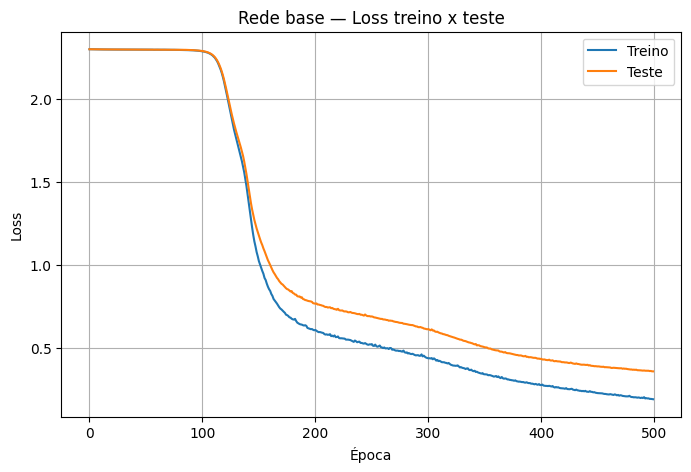

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(resultado_base["loss_train"], label="Treino")
plt.plot(resultado_base["loss_test"], label="Teste")

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Rede base — Loss treino x teste")

plt.legend()
plt.grid(True)
plt.show()

# Início dos Experimentos

A partir deste ponto, você deverá realizar os experimentos do checkpoint.

A rede base já está funcionando com:

- 2 camadas ocultas
- ReLU como função de ativação nas camadas ocultas
- softmax na saída
- cross-entropy como função de loss

Seu papel agora é **modificar essa rede e investigar o comportamento dela**.

---

## Experimento 1 — ReLU x Sigmoide

Neste experimento, você deverá comparar o uso de:

- ReLU
- Sigmoide

nas camadas ocultas da rede.

### O que deve ser feito:

- Alterar a função de ativação no forward
- Ajustar o backpropagation para usar a derivada correta
- Treinar a rede nas duas configurações

### Atenção:

- Use a mesma arquitetura (mesmo número de camadas e neurônios)
- Compare apenas o efeito da função de ativação
- Registre os resultados obtidos

---

## Experimento 2 — Número de camadas ocultas

Neste experimento, você deverá comparar redes com:

- 1 camada oculta
- 2 camadas ocultas (já implementada)
- 3 camadas ocultas

Utilize **ReLU** como função de ativação nas camadas ocultas.

### O que deve ser feito:

- Adaptar o código para permitir diferentes números de camadas
- Garantir que forward e backpropagation estejam consistentes com a arquitetura escolhida
- Treinar cada configuração

---

## Parâmetros livres

Em ambos os experimentos, você pode ajustar:

- número de neurônios em cada camada
- learning rate
- batch size
- número máximo de épocas
- inicialização dos pesos (opcional)

---

## Base de dados

Para os experimentos:

- utilize a base reduzida (`X_train_exp`, `Y_train_exp`)

Para a tentativa final de melhor desempenho:

- utilize a base completa (`X_train_flat`, `y_train_oh`)

---

## Registro dos resultados

Você deverá registrar:

- loss de treino e teste
- acurácia de treino e teste
- gráficos de loss ao longo das épocas

Essas evidências deverão aparecer no notebook e no relatório.

---

## Objetivo final

Após realizar os experimentos, você deverá:

- escolher a melhor configuração encontrada
- treinar a rede na base completa
- obter a maior acurácia possível no conjunto de teste

---

## Importante

Este não é um exercício de copiar código.

Você deverá:

- modificar a rede existente
- testar diferentes configurações
- observar o comportamento do treinamento

Erros fazem parte do processo. Ajustes também.

O foco aqui é entender como a rede responde às mudanças feitas.

## Entrega do Checkpoint

A entrega será feita via Google Forms.

Você deverá enviar:

### 1. Notebook (.ipynb)

- O notebook deve conter **todas as execuções realizadas**.
- As saídas (outputs) devem estar visíveis:
  - prints
  - gráficos
  - métricas de desempenho

---

### 2. Relatório em PDF (máx. 2 páginas)

O relatório deve conter:

**Página 1 — Experimento 1 (ReLU x Sigmoide)**
- configurações utilizadas
- gráfico(s) de loss
- acurácia final
- conclusão breve

**Página 2 — Experimento 2 (1, 2 e 3 camadas ocultas)**
- configurações utilizadas
- comparação dos resultados
- acurácia final
- conclusão breve

---

### 3. Informações no Forms

Você deverá preencher:

- melhor acurácia obtida no teste
- configuração da melhor rede:
  - número de camadas
  - número de neurônios
  - função de ativação
  - learning rate
  - batch size
  - número de épocas

---

## Organização do Notebook

A partir deste ponto do notebook:

- **não altere o código já fornecido acima**
- qualquer modificação deve ser feita **a partir daqui**

---

### Regras

1. Crie novas células de código para seus testes  
2. Crie células de Markdown explicando:

   - o que foi modificado
   - por que você fez essa modificação
   - qual experimento está sendo realizado

3. Organize o notebook de forma que seja possível identificar claramente:

   - Experimento 1
   - Experimento 2
   - Teste final com a melhor configuração

---

### Exemplo de organização

```markdown
## Experimento 1 — ReLU

(alterações realizadas...)

(código...)

(resultados...)

## Experimento 1 — Sigmoide

(alterações realizadas...)

(código...)

(resultados...)
```

---

### Importante
Não é necessário escrever textos longos
O foco está nos testes realizados e nos resultados obtidos
O notebook deve permitir que outra pessoa entenda o que foi feito

---

###Observação final

Alterações feitas sem explicação no notebook podem não ser consideradas na avaliação.

A clareza da organização faz parte do trabalho.

## Critérios de Avaliação

- Execução dos experimentos propostos  
- Evidência dos resultados (gráficos e métricas)  
- Organização e clareza do notebook  
- Coerência entre resultados e conclusões  
- Execução final com a base completa do MNIST  

---

## Bônus

### Bônus individual (+0,5)

Os 10% dos alunos com maior acurácia no conjunto de teste completo do MNIST (considerando todas as turmas) receberão um bônus de **+0,5 ponto**.

---

### Bônus por turma (+0,3)

A turma com a maior acurácia média no conjunto de teste completo receberá um bônus de **+0,3 ponto** para todos os seus integrantes.

---

### Regra de aplicação do bônus

- A nota do Checkpoint 2 é limitada a **10,0 pontos**.
- Caso a soma da nota com o(s) bônus ultrapasse 10,0, o valor excedente será convertido em crédito.
- Esse crédito poderá ser utilizado em outro checkpoint da disciplina (preferencialmente no CP3, ou no CP1).
- O crédito deve ser utilizado uma única vez.

---

## Observação

O bônus é adicional e não prejudica alunos que não o obtiverem.

O objetivo é incentivar a exploração de diferentes configurações da rede e a busca por melhor desempenho.

---

## Atenção ao tempo de execução

O treinamento da rede neural, especialmente com a base completa do MNIST, pode ser demorado.

Ao longo do trabalho, você precisará equilibrar:

- número de tentativas realizadas  
- complexidade da rede (camadas e neurônios)  
- quantidade de épocas  
- tempo disponível  

Recomenda-se:

- usar a base reduzida para explorar e testar ideias  
- reservar a base completa para poucas tentativas finais  
- evitar configurações excessivamente grandes sem necessidade  

Parte do desafio deste checkpoint é justamente tomar boas decisões considerando esse *trade-off*.


## Experimento 1 — Comparação: ReLU x Sigmoide

Mantemos 2 camadas ocultas com a mesma arquitetura.
Alteramos apenas a função de ativação nas camadas ocultas.
O backpropagation é ajustado para usar a derivada correta em cada caso.

In [ ]:
# Experimento 1 — Forward com ativação configurável (2 camadas ocultas)

def forward_exp1(X, params, activation="relu"):
    W1, b1 = params["W1"], params["b1"]
    W2, b2 = params["W2"], params["b2"]
    W3, b3 = params["W3"], params["b3"]

    # Seleciona a função de ativação
    if activation == "relu":
        act_fn = relu
    elif activation == "sigmoid":
        act_fn = sigmoid
    else:
        raise ValueError(f"Ativação desconhecida: {activation}")

    Z1 = W1 @ X + b1
    A1 = act_fn(Z1)

    Z2 = W2 @ A1 + b2
    A2 = act_fn(Z2)

    Z3 = W3 @ A2 + b3
    A3 = softmax(Z3)

    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2, "Z3": Z3, "A3": A3}
    return A3, cache


# Experimento 1 — Backprop com derivada configurável (2 camadas ocultas)

def backpropagate_exp1(X, Y, params, cache, activation="relu"):
    W3 = params["W3"]
    W2 = params["W2"]

    A1 = cache["A1"]
    A2 = cache["A2"]
    A3 = cache["A3"]

    m = X.shape[1]

    # Seleciona a derivada correta
    if activation == "relu":
        deriv_fn = relu_derivative
    elif activation == "sigmoid":
        deriv_fn = sigmoid_derivative
    else:
        raise ValueError(f"Ativação desconhecida: {activation}")

    # Camada de saída
    dZ3 = (A3 - Y) / m
    dW3 = dZ3 @ A2.T
    db3 = np.sum(dZ3, axis=1, keepdims=True)

    # Camada oculta 2
    dA2 = W3.T @ dZ3
    dZ2 = dA2 * deriv_fn(A2)
    dW2 = dZ2 @ A1.T
    db2 = np.sum(dZ2, axis=1, keepdims=True)

    # Camada oculta 1
    dA1 = W2.T @ dZ2
    dZ1 = dA1 * deriv_fn(A1)
    dW1 = dZ1 @ X.T
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    grads = {
        "dW1": dW1, "db1": db1,
        "dW2": dW2, "db2": db2,
        "dW3": dW3, "db3": db3
    }
    return grads

In [ ]:
# Experimento 1 — Função de treino com ativação configurável

def train_exp1(
    X_train, Y_train, X_test, Y_test,
    activation="relu",
    n_h1=128, n_h2=64,
    learning_rate=0.005,
    num_epochs=500,
    batch_size=128,
    patience=50,
    print_every=50
):
    n_x = X_train.shape[0]
    n_y = Y_train.shape[0]

    params = initialize_parameters(n_x, n_h1, n_h2, n_y)

    best_test_loss = float("inf")
    epochs_no_improve = 0
    best_params = None
    loss_train, loss_test = [], []

    print(f"\n[Experimento 1 — {activation.upper()}]")
    print(f"n_h1={n_h1}, n_h2={n_h2}, lr={learning_rate}, batch={batch_size}, patience={patience}")

    for epoch in range(num_epochs):
        mini_batches = create_mini_batches(X_train, Y_train, batch_size)
        epoch_loss_train = 0

        for mb_X, mb_Y in mini_batches:
            A3, cache = forward_exp1(mb_X, params, activation)
            loss = compute_loss(A3, mb_Y)
            epoch_loss_train += loss
            grads = backpropagate_exp1(mb_X, mb_Y, params, cache, activation)
            params = update_parameters(params, grads, learning_rate)

        avg_loss_train = epoch_loss_train / len(mini_batches)
        loss_train.append(avg_loss_train)

        A3_test, _ = forward_exp1(X_test, params, activation)
        loss_v = compute_loss(A3_test, Y_test)
        loss_test.append(loss_v)

        if loss_v < best_test_loss:
            best_test_loss = loss_v
            epochs_no_improve = 0
            best_params = {k: v.copy() for k, v in params.items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"  Early stopping na época {epoch}.")
                params = best_params
                break

        if epoch % print_every == 0:
            print(f"  Época {epoch:4d} | Loss treino: {avg_loss_train:.4f} | Loss teste: {loss_v:.4f}")

    # Acurácia final
    A3_tr, _ = forward_exp1(X_train, params, activation)
    acc_train = np.mean(np.argmax(A3_tr, axis=0) == np.argmax(Y_train, axis=0)) * 100

    A3_te, _ = forward_exp1(X_test, params, activation)
    acc_test = np.mean(np.argmax(A3_te, axis=0) == np.argmax(Y_test, axis=0)) * 100

    print(f"  Acurácia treino: {acc_train:.2f}% | Acurácia teste: {acc_test:.2f}%")

    return {
        "params": params,
        "loss_train": loss_train,
        "loss_test": loss_test,
        "accuracy_train": acc_train,
        "accuracy_test": acc_test,
        "activation": activation
    }

In [ ]:
# Treinamento com ReLU
resultado_relu = train_exp1(
    X_train_exp, Y_train_exp, X_test_exp, Y_test_exp,
    activation="relu",
    n_h1=128, n_h2=64,
    learning_rate=0.005,
    num_epochs=500,
    batch_size=128,
    patience=50
)

# Treinamento com Sigmoide — mesma arquitetura, só muda a ativação
resultado_sigmoid = train_exp1(
    X_train_exp, Y_train_exp, X_test_exp, Y_test_exp,
    activation="sigmoid",
    n_h1=128, n_h2=64,
    learning_rate=0.005,
    num_epochs=500,
    batch_size=128,
    patience=50
)


[Experimento 1 — RELU]
n_h1=128, n_h2=64, lr=0.005, batch=128, patience=50
  Época    0 | Loss treino: 2.3025 | Loss teste: 2.3024
  Época   50 | Loss treino: 2.2979 | Loss teste: 2.2987
  Época  100 | Loss treino: 1.3661 | Loss teste: 1.4191
  Época  150 | Loss treino: 0.5824 | Loss teste: 0.7257
  Época  200 | Loss treino: 0.4689 | Loss teste: 0.6265
  Época  250 | Loss treino: 0.3594 | Loss teste: 0.5084
  Época  300 | Loss treino: 0.2845 | Loss teste: 0.4272
  Época  350 | Loss treino: 0.2338 | Loss teste: 0.3801
  Época  400 | Loss treino: 0.1970 | Loss teste: 0.3445
  Época  450 | Loss treino: 0.1667 | Loss teste: 0.3194
  Acurácia treino: 96.34% | Acurácia teste: 90.50%

[Experimento 1 — SIGMOID]
n_h1=128, n_h2=64, lr=0.005, batch=128, patience=50
  Época    0 | Loss treino: 2.3022 | Loss teste: 2.3020
  Época   50 | Loss treino: 2.3007 | Loss teste: 2.3010
  Early stopping na época 88.
  Acurácia treino: 11.27% | Acurácia teste: 11.70%


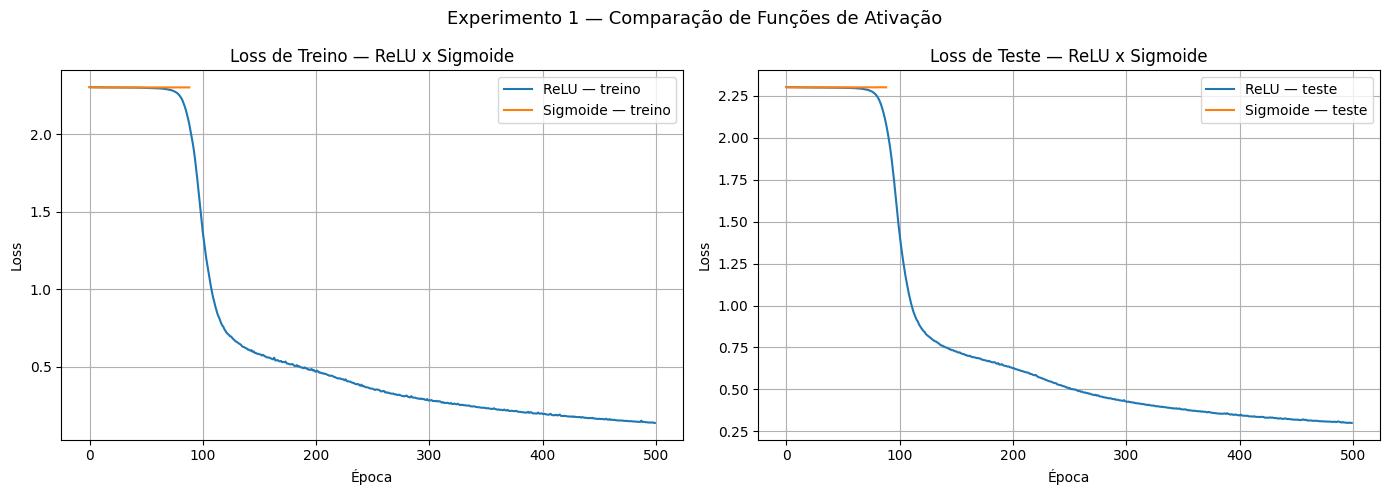


Resumo Experimento 1:
  ReLU     — Acurácia treino: 96.34%  | Acurácia teste: 90.50%
  Sigmoide — Acurácia treino: 11.27% | Acurácia teste: 11.70%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(resultado_relu["loss_train"],    label="ReLU — treino",    color="tab:blue")
axes[0].plot(resultado_sigmoid["loss_train"], label="Sigmoide — treino", color="tab:orange")
axes[0].set_title("Loss de Treino — ReLU x Sigmoide")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(resultado_relu["loss_test"],    label="ReLU — teste",    color="tab:blue")
axes[1].plot(resultado_sigmoid["loss_test"], label="Sigmoide — teste", color="tab:orange")
axes[1].set_title("Loss de Teste — ReLU x Sigmoide")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Experimento 1 — Comparação de Funções de Ativação", fontsize=13)
plt.tight_layout()
plt.show()

print("\nResumo Experimento 1:")
print(f"  ReLU     — Acurácia treino: {resultado_relu['accuracy_train']:.2f}%  | Acurácia teste: {resultado_relu['accuracy_test']:.2f}%")
print(f"  Sigmoide — Acurácia treino: {resultado_sigmoid['accuracy_train']:.2f}% | Acurácia teste: {resultado_sigmoid['accuracy_test']:.2f}%")

## Experimento 2 — Comparação: 1, 2 e 3 camadas ocultas

Usamos ReLU como ativação em todas as configurações.
Apenas o número de camadas ocultas varia entre os testes.
Forward e backpropagation foram generalizados para suportar arquiteturas diferentes.

In [ ]:
# Experimento 2 — Inicialização genérica para N camadas ocultas

def initialize_parameters_generic(layer_dims):
    """
    layer_dims: lista com o tamanho de cada camada.
    Exemplo para 2 camadas ocultas: [784, 128, 64, 10]
    """
    np.random.seed(42)
    params = {}
    L = len(layer_dims) - 1  # número de camadas com pesos

    for l in range(1, L + 1):
        params[f"W{l}"] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
        params[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return params


# Experimento 2 — Forward genérico com ReLU nas ocultas e Softmax na saída

def forward_generic(X, params, num_layers):
    cache = {"A0": X}

    for l in range(1, num_layers):  # camadas ocultas
        W = params[f"W{l}"]
        b = params[f"b{l}"]
        Z = W @ cache[f"A{l-1}"] + b
        A = relu(Z)
        cache[f"Z{l}"] = Z
        cache[f"A{l}"] = A

    # Camada de saída
    W = params[f"W{num_layers}"]
    b = params[f"b{num_layers}"]
    Z = W @ cache[f"A{num_layers-1}"] + b
    A = softmax(Z)
    cache[f"Z{num_layers}"] = Z
    cache[f"A{num_layers}"] = A

    return A, cache


# Experimento 2 — Backprop genérico

def backpropagate_generic(Y, params, cache, num_layers):
    grads = {}
    m = cache["A0"].shape[1]

    # Gradiente da camada de saída
    A_out = cache[f"A{num_layers}"]
    dZ = (A_out - Y) / m
    grads[f"dW{num_layers}"] = dZ @ cache[f"A{num_layers-1}"].T
    grads[f"db{num_layers}"] = np.sum(dZ, axis=1, keepdims=True)

    # Gradiente das camadas ocultas (de trás pra frente)
    for l in range(num_layers - 1, 0, -1):
        W_next = params[f"W{l+1}"]
        dA = W_next.T @ dZ
        dZ = dA * relu_derivative(cache[f"A{l}"])
        grads[f"dW{l}"] = dZ @ cache[f"A{l-1}"].T
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True)

    return grads


# Experimento 2 — update_parameters genérico

def update_parameters_generic(params, grads, learning_rate, num_layers):
    for l in range(1, num_layers + 1):
        params[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
        params[f"b{l}"] -= learning_rate * grads[f"db{l}"]
    return params

In [ ]:
# Experimento 2 — Função de treino genérica

def train_exp2(
    X_train, Y_train, X_test, Y_test,
    layer_dims,
    learning_rate=0.005,
    num_epochs=500,
    batch_size=128,
    patience=50,
    print_every=50
):
    """
    layer_dims: lista completa da arquitetura.
    Exemplos:
      1 camada oculta: [784, 128, 10]
      2 camadas ocultas: [784, 128, 128, 10]
      3 camadas ocultas: [784, 128, 128, 128, 10]
    """
    num_layers = len(layer_dims) - 1  # total de camadas com pesos
    params = initialize_parameters_generic(layer_dims)

    best_test_loss = float("inf")
    epochs_no_improve = 0
    best_params = None
    loss_train, loss_test = [], []

    n_hidden = num_layers - 1
    print(f"\n[Experimento 2 — {n_hidden} camada(s) oculta(s)]")
    print(f"Arquitetura: {layer_dims} | lr={learning_rate} | batch={batch_size} | patience={patience}")

    for epoch in range(num_epochs):
        mini_batches = create_mini_batches(X_train, Y_train, batch_size)
        epoch_loss_train = 0

        for mb_X, mb_Y in mini_batches:
            A_out, cache = forward_generic(mb_X, params, num_layers)
            loss = compute_loss(A_out, mb_Y)
            epoch_loss_train += loss
            grads = backpropagate_generic(mb_Y, params, cache, num_layers)
            params = update_parameters_generic(params, grads, learning_rate, num_layers)

        avg_loss_train = epoch_loss_train / len(mini_batches)
        loss_train.append(avg_loss_train)

        A_test, _ = forward_generic(X_test, params, num_layers)
        loss_v = compute_loss(A_test, Y_test)
        loss_test.append(loss_v)

        if loss_v < best_test_loss:
            best_test_loss = loss_v
            epochs_no_improve = 0
            best_params = {k: v.copy() for k, v in params.items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"  Early stopping na época {epoch}.")
                params = best_params
                break

        if epoch % print_every == 0:
            print(f"  Época {epoch:4d} | Loss treino: {avg_loss_train:.4f} | Loss teste: {loss_v:.4f}")

    # Acurácia final
    A_tr, _ = forward_generic(X_train, params, num_layers)
    acc_train = np.mean(np.argmax(A_tr, axis=0) == np.argmax(Y_train, axis=0)) * 100

    A_te, _ = forward_generic(X_test, params, num_layers)
    acc_test = np.mean(np.argmax(A_te, axis=0) == np.argmax(Y_test, axis=0)) * 100

    print(f"  Acurácia treino: {acc_train:.2f}% | Acurácia teste: {acc_test:.2f}%")

    return {
        "layer_dims": layer_dims,
        "loss_train": loss_train,
        "loss_test": loss_test,
        "accuracy_train": acc_train,
        "accuracy_test": acc_test,
        "n_hidden": n_hidden
    }

In [ ]:
resultado_1camada = train_exp2(
    X_train_exp, Y_train_exp, X_test_exp, Y_test_exp,
    layer_dims=[784, 128, 10],
    learning_rate=0.005, num_epochs=500, batch_size=128, patience=50
)



[Experimento 2 — 1 camada(s) oculta(s)]
Arquitetura: [784, 128, 10] | lr=0.005 | batch=128 | patience=50
  Época    0 | Loss treino: 2.3007 | Loss teste: 2.2986
  Época   50 | Loss treino: 0.4800 | Loss teste: 0.5839
  Época  100 | Loss treino: 0.3325 | Loss teste: 0.4434
  Época  150 | Loss treino: 0.2845 | Loss teste: 0.4007
  Época  200 | Loss treino: 0.2545 | Loss teste: 0.3762
  Época  250 | Loss treino: 0.2306 | Loss teste: 0.3588
  Época  300 | Loss treino: 0.2114 | Loss teste: 0.3444
  Época  350 | Loss treino: 0.1951 | Loss teste: 0.3323
  Época  400 | Loss treino: 0.1770 | Loss teste: 0.3211
  Época  450 | Loss treino: 0.1655 | Loss teste: 0.3117
  Acurácia treino: 95.85% | Acurácia teste: 90.45%


In [ ]:
resultado_2camadas = train_exp2(
    X_train_exp, Y_train_exp, X_test_exp, Y_test_exp,
    layer_dims=[784, 128, 128, 10],
    learning_rate=0.005, num_epochs=500, batch_size=128, patience=50
)


[Experimento 2 — 2 camada(s) oculta(s)]
Arquitetura: [784, 128, 128, 10] | lr=0.005 | batch=128 | patience=50
  Época    0 | Loss treino: 2.3026 | Loss teste: 2.3024
  Época   50 | Loss treino: 2.2899 | Loss teste: 2.2911
  Época  100 | Loss treino: 0.7411 | Loss teste: 0.8519
  Época  150 | Loss treino: 0.5062 | Loss teste: 0.6517
  Época  200 | Loss treino: 0.3797 | Loss teste: 0.5199
  Época  250 | Loss treino: 0.3122 | Loss teste: 0.4471
  Época  300 | Loss treino: 0.2619 | Loss teste: 0.3952
  Época  350 | Loss treino: 0.2135 | Loss teste: 0.3532
  Época  400 | Loss treino: 0.1786 | Loss teste: 0.3230
  Época  450 | Loss treino: 0.1576 | Loss teste: 0.3040
  Acurácia treino: 96.77% | Acurácia teste: 91.35%


In [ ]:
resultado_3camadas = train_exp2(
    X_train_exp, Y_train_exp, X_test_exp, Y_test_exp,
    layer_dims=[784, 128, 128, 128, 10],
    learning_rate=0.005, num_epochs=500, batch_size=128, patience=100 # Patience alterada para a execução ocorrer de maneira correta

)


[Experimento 2 — 3 camada(s) oculta(s)]
Arquitetura: [784, 128, 128, 128, 10] | lr=0.005 | batch=128 | patience=100
  Época    0 | Loss treino: 2.3025 | Loss teste: 2.3024
  Época   50 | Loss treino: 2.3004 | Loss teste: 2.3010
  Época  100 | Loss treino: 2.3005 | Loss teste: 2.3010
  Época  150 | Loss treino: 2.3005 | Loss teste: 2.3009
  Época  200 | Loss treino: 2.3000 | Loss teste: 2.3010
  Época  250 | Loss treino: 2.3003 | Loss teste: 2.3009
  Época  300 | Loss treino: 2.2998 | Loss teste: 2.3006
  Época  350 | Loss treino: 2.2987 | Loss teste: 2.2997
  Época  400 | Loss treino: 2.2907 | Loss teste: 2.2921
  Época  450 | Loss treino: 1.0901 | Loss teste: 1.1858
  Acurácia treino: 74.46% | Acurácia teste: 68.40%


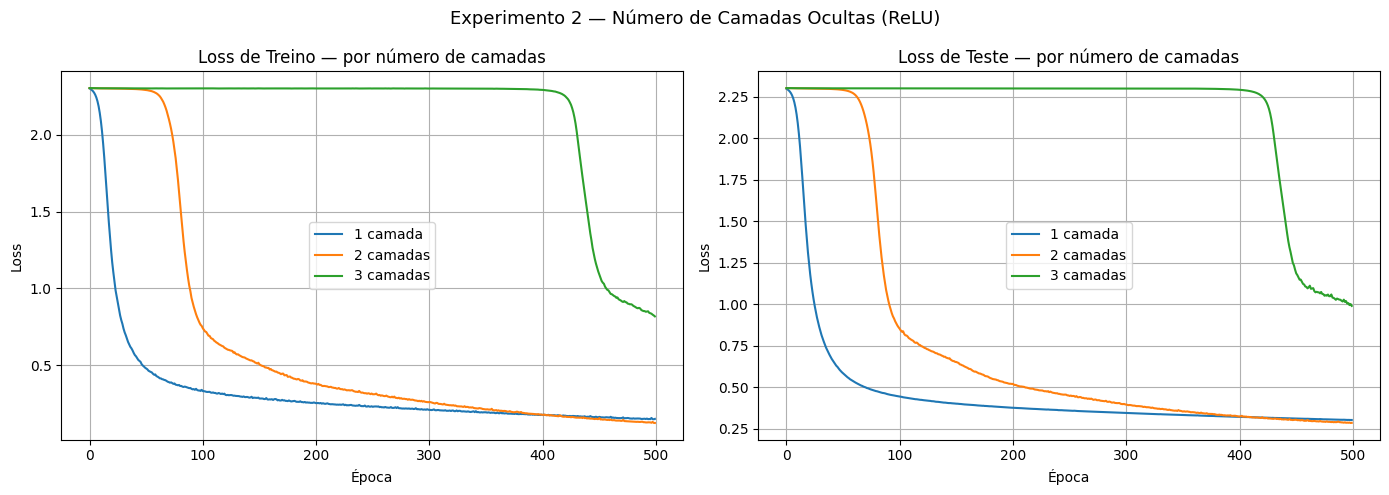


Resumo Experimento 2:
  1 camada: Acurácia treino: 95.85% | Acurácia teste: 90.45%
  2 camadas: Acurácia treino: 96.77% | Acurácia teste: 91.35%
  3 camadas: Acurácia treino: 74.46% | Acurácia teste: 68.40%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cores = {"1 camada": "tab:blue", "2 camadas": "tab:orange", "3 camadas": "tab:green"}
resultados = {
    "1 camada": resultado_1camada,
    "2 camadas": resultado_2camadas,
    "3 camadas": resultado_3camadas
}

for label, res in resultados.items():
    axes[0].plot(res["loss_train"], label=label, color=cores[label])
    axes[1].plot(res["loss_test"], label=label, color=cores[label])

axes[0].set_title("Loss de Treino — por número de camadas")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Loss de Teste — por número de camadas")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Experimento 2 — Número de Camadas Ocultas (ReLU)", fontsize=13)
plt.tight_layout()
plt.show()

print("\nResumo Experimento 2:")
for label, res in resultados.items():
    print(f"  {label}: Acurácia treino: {res['accuracy_train']:.2f}% | Acurácia teste: {res['accuracy_test']:.2f}%")